## เขียนเล่นไม่ต้องเข้าดูก้อได้

In [5]:
import numpy as np
import pandas as pd
import os
import kagglehub as kaggle
import seaborn as sns
import matplotlib.pyplot as plt
#print(kagglehub.__version__)

KGAT_6afe815653c246d1757bd73d94aa539e

In [6]:
kaggle.login()

In [8]:
# Download latest version
path = kaggle.competition_download('playground-series-s6e11')

print("Path to competition files:", path)

Path to competition files: /Users/nathanonkhueanta/.cache/kagglehub/competitions/playground-series-s6e11


In [9]:
import os

files = os.listdir(path)

for file in files:
    print(file)

test.csv
train.csv
sample_submission.csv


In [10]:
test = pd.read_csv(os.path.join(path, 'test.csv'))
train = pd.read_csv(os.path.join(path, 'train.csv'))
sample_submission = pd.read_csv(os.path.join(path, 'sample_submission.csv'))

In [11]:
train.columns

Index(['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
       'distance_from_home_km', 'card_age_months', 'customer_age',
       'account_balance_usd', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'merchant_risk_score',
       'prior_disputes', 'merchant_category', 'card_type', 'auth_method',
       'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant',
       'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt', 'is_fraud'],
      dtype='str')

In [12]:
len(test.columns)

25

In [13]:
train[:1]

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0


In [14]:
test

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt
0,699960,28.21,4.52,4,17.87,37,45,1483.49,0,15.4,...,Visa,OTP,Online,iPhone,False,False,False,False,False,False
1,699961,644.90,5.48,1,6.68,52,28,2183.64,0,11.2,...,RuPay,PIN,Contactless,Android Phone,False,False,False,False,False,False
2,699962,20.53,12.20,3,15.39,44,75,1208.59,0,20.8,...,Visa,No Authentication,Online,iPhone,False,False,False,False,False,False
3,699963,10.83,6.90,2,44.34,50,54,1790.85,0,9.2,...,Mastercard,PIN,Contactless,Mac,False,False,False,False,False,False
4,699964,19.00,0.63,3,25.22,50,66,1676.18,0,20.0,...,Mastercard,PIN,In-App,Android Phone,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
299979,999939,26.55,4.48,0,8.73,43,61,496.31,1,2.2,...,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False
299980,999940,8.22,2.68,5,1.22,40,39,2717.16,0,18.2,...,Mastercard,3D Secure,In-App,POS Terminal,False,True,False,False,False,False
299981,999941,44.76,4.36,4,35.49,44,27,1797.59,1,30.5,...,Visa,3D Secure,Contactless,Android Phone,False,False,False,False,False,False
299982,999942,3.61,1.74,3,16.86,40,28,3489.65,0,11.1,...,Visa,Biometric,POS,Android Phone,False,False,False,False,False,False


##

##

## Data Analysis

In [16]:
Data_total = train.copy()
len(Data_total.columns)

26

In [17]:
Data_total.dtypes

id                                int64
amount_usd                      float64
hours_since_last_txn            float64
txn_count_last_24h                int64
distance_from_home_km           float64
card_age_months                   int64
customer_age                      int64
account_balance_usd             float64
cvv_retry_count                   int64
velocity_score                  float64
time_of_day_hour                  int64
day_of_week                       int64
merchant_risk_score             float64
prior_disputes                    int64
merchant_category                   str
card_type                           str
auth_method                         str
channel                             str
device_type                         str
is_foreign_transaction             bool
is_new_merchant                    bool
used_vpn                           bool
ip_country_mismatch                bool
billing_shipping_mismatch          bool
is_ai_generated_scam_attempt       bool


In [18]:
Data_total.select_dtypes(include=[int, float])

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
699955,699955,715.39,4.10,3,3.24,45,31,1598.50,0,20.8,1,3,54.8,0,0.0
699956,699956,32.28,0.04,6,8.56,44,81,2149.48,1,65.0,5,1,43.9,0,0.0
699957,699957,22.95,4.99,4,4.23,37,69,959.88,0,19.3,4,6,38.7,0,0.0
699958,699958,14.19,1.86,4,28.08,40,72,1362.85,0,31.0,12,3,32.3,0,0.0


In [19]:
Data_total.select_dtypes(include=[str, object])

,merchant_category,card_type,auth_method,channel,device_type
0,Groceries,Mastercard,OTP,POS,iPhone
1,Online Retail,Visa,PIN,In-App,Android Phone
2,Utilities,Visa,OTP,Online,Tablet
3,Groceries,Mastercard,3D Secure,POS,Android Phone
4,Electronics,Visa,3D Secure,Online,Windows PC
...,...,...,...,...,...
699955,Travel,Mastercard,3D Secure,POS,Windows PC
699956,Restaurants,Mastercard,No Authentication,Online,iPhone
699957,Online Retail,Mastercard,Biometric,Online,Android Phone
699958,Groceries,Mastercard,PIN,ATM,Windows PC


In [20]:
Data_total.select_dtypes(include=[bool])

,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt
0,False,False,False,False,False,False
1,False,False,False,False,False,False
2,False,False,True,False,False,False
3,False,False,False,False,False,False
4,False,False,False,False,False,False
...,...,...,...,...,...,...
699955,False,False,False,False,False,False
699956,False,False,False,False,False,False
699957,False,False,True,False,False,False
699958,False,False,True,False,False,False


In [21]:
fraud_aiscam = Data_total[["is_fraud","is_ai_generated_scam_attempt" ]]
fraud_aiscam["new_ai_scam_indicator"] = (
    fraud_aiscam["is_ai_generated_scam_attempt"].astype(int)
)

In [22]:
fraud_aiscam[['new_ai_scam_indicator']].value_counts()

new_ai_scam_indicator
0                        697661
1                          2299
Name: count, dtype: int64

In [23]:
fraud_aiscam[["is_fraud", "new_ai_scam_indicator"]].corr()

,is_fraud,new_ai_scam_indicator
is_fraud,1.000000,0.060719
new_ai_scam_indicator,0.060719,1.000000


In [24]:
Data_total[["is_fraud"]]

,is_fraud
0,0.0
1,0.0
2,0.0
3,0.0
4,0.0
...,...
699955,0.0
699956,0.0
699957,0.0
699958,0.0


In [25]:
fraud_int = Data_total.select_dtypes(include=[int,float])
fraud_int_corr = fraud_int.corr()

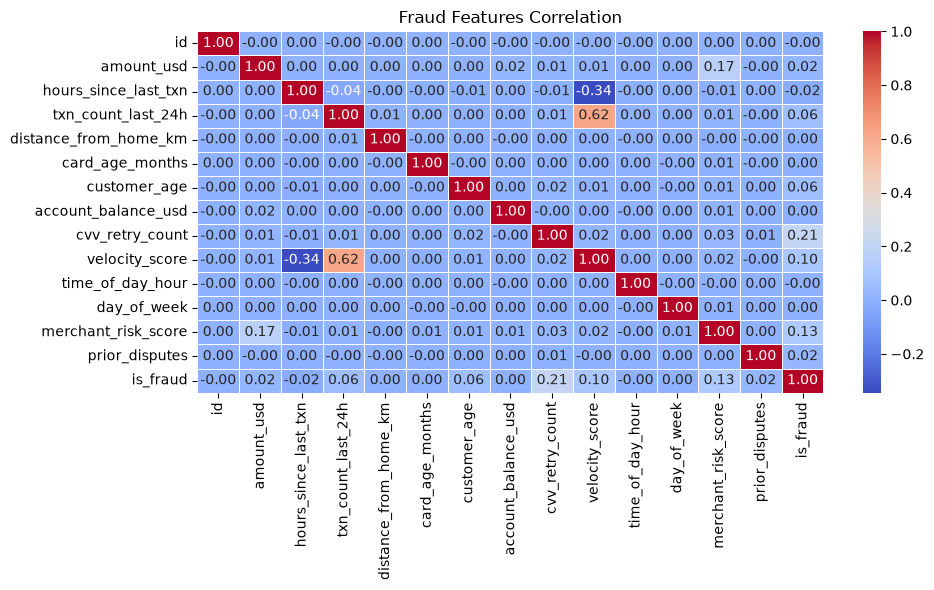

In [26]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    fraud_int_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Fraud Features Correlation")
plt.tight_layout()
plt.show()

In [59]:
fraud_int.describe()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,is_fraud
count,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000
mean,349979.500000,79.893068,6.633734,2.984092,13.587575,46.862982,51.430286,2064.998070,0.085472,18.929445,11.761915,2.981733,35.217648,0.152769,0.016700
std,202061.191549,205.173538,6.290133,1.498998,11.617325,5.579190,17.899150,3400.132922,0.289524,10.864385,6.869164,2.001652,12.628361,0.381126,0.128143
min,0.000000,1.000000,0.010000,0.000000,0.000000,25.000000,18.000000,58.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,174989.750000,15.810000,2.110000,2.000000,4.430000,43.000000,38.000000,834.120000,0.000000,11.400000,6.000000,1.000000,26.400000,0.000000,0.000000
50%,349979.500000,27.250000,4.730000,3.000000,10.220000,47.000000,52.000000,1382.740000,0.000000,18.600000,12.000000,3.000000,34.200000,0.000000,0.000000
75%,524969.250000,43.110000,9.190000,4.000000,19.750000,51.000000,66.000000,2517.020000,0.000000,26.000000,18.000000,5.000000,42.700000,0.000000,0.000000
max,699959.000000,6872.690000,51.980000,11.000000,57.930000,73.000000,81.000000,99701.390000,3.000000,72.900000,23.000000,6.000000,100.000000,4.000000,1.000000


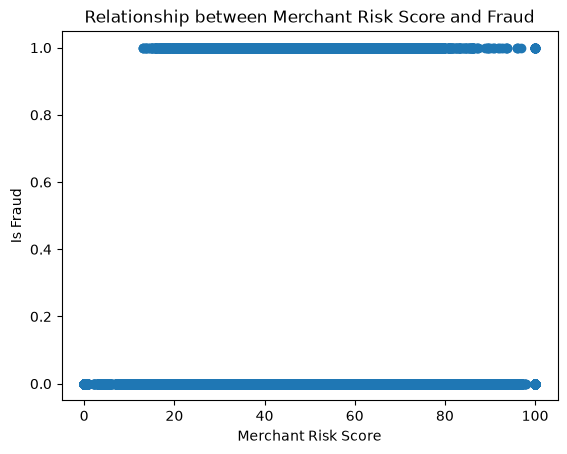

,merchant_risk_score,is_fraud
merchant_risk_score,1.000000,0.125391
is_fraud,0.125391,1.000000


In [66]:
plt.scatter(fraud_int["merchant_risk_score"], fraud_int["is_fraud"])
plt.xlabel("Merchant Risk Score")
plt.ylabel("Is Fraud")
plt.title("Relationship between Merchant Risk Score and Fraud")
plt.show()

print("=="*50)
fraud_int[["merchant_risk_score", "is_fraud"]].corr()

##

##

##

## Selected feature using Random forest

In [46]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [34]:
feature_train_data = fraud_int.drop(columns=["is_fraud","id"])
target_train_data = fraud_int["is_fraud"]
feature_train_data.isna().sum()

amount_usd               0
hours_since_last_txn     0
txn_count_last_24h       0
distance_from_home_km    0
card_age_months          0
customer_age             0
account_balance_usd      0
cvv_retry_count          0
velocity_score           0
time_of_day_hour         0
day_of_week              0
merchant_risk_score      0
prior_disputes           0
dtype: int64

In [35]:
feature_train_data = np.array(feature_train_data)
feature_train_data.shape , target_train_data.shape

((699960, 13), (699960,))

In [38]:
rg_model = RandomForestRegressor(n_estimators=100, random_state=42)
rg_model.fit(feature_train_data, target_train_data)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [41]:
Data_test = test.select_dtypes(include=[int,float])
Data_test = np.array(Data_test.drop(columns=["id"]))
Data_test.shape

(299984, 13)

In [44]:
rg_model.predict(Data_test)

array([0.  , 0.  , 0.  , ..., 0.04, 0.  , 0.01], shape=(299984,))

In [47]:
mean_squared_error(target_train_data, rg_model.predict(feature_train_data))

0.002057216698097034

In [51]:
target_test_data = np.array(sample_submission["is_fraud"])
target_test_data.shape

(299984,)

In [52]:
mean_squared_error(target_test_data, rg_model.predict(Data_test))

0.0034372824951865565

In [53]:
rg_model.feature_importances_

array([0.11162893, 0.09999423, 0.03292562, 0.10472413, 0.06133583,
       0.07339292, 0.11063052, 0.05312988, 0.11753231, 0.05788173,
       0.03559693, 0.12856673, 0.01266022])

Text(0.5, 1.0, 'Feature Importances from Random Forest Model')

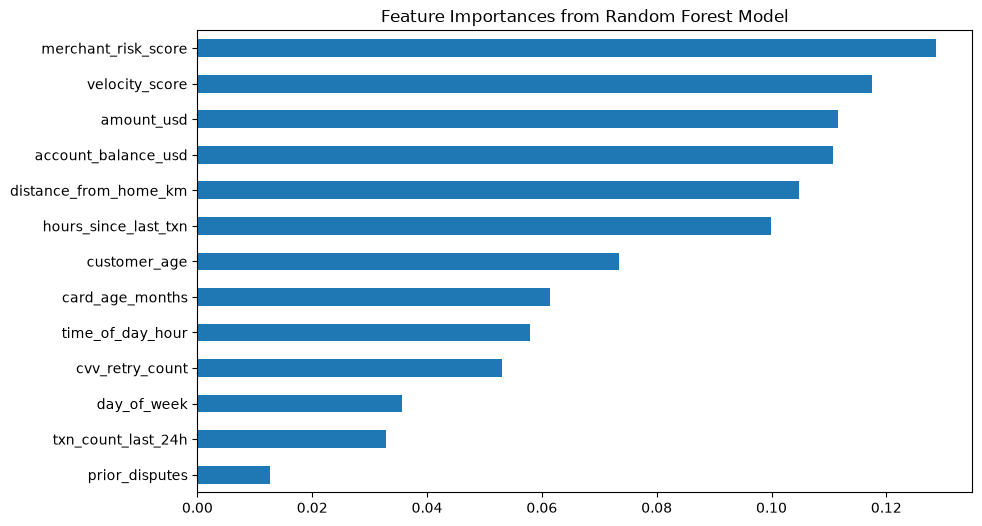

In [57]:
plot_importances = pd.Series(rg_model.feature_importances_, index=fraud_int.drop(columns=["is_fraud", "id"]).columns)
plot_importances.sort_values(ascending=True, inplace=True)
plot_importances.plot(kind='barh',figsize=(10, 6))
plt.title("Feature Importances from Random Forest Model")